# 02 — Authors' protein table: sample map, sex, and genotype-like proteins

Before re-searching the raw spectra, this notebook uses the tables released by the authors (Kim et al. 2022) to

1. assign every sample to its TMT set and channel (not given in the publication),
2. infer donor sex from Y-chromosome proteins,
3. scan the proteome for proteins whose abundance splits the donors into two clearly separated clusters, as expected for common germline deletions or destabilising variants.

Inputs  
- `data_raw/suicide_cohort_protein_list_Proteins.txt` — Proteome Discoverer protein table from PRIDE (40 TMT channels)  
- `data_external/Kim2022_MOESM2_ESM.xlsx` — Supplementary Table S2 of the publication (36 samples, labelled by group)

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

SUPP = ROOT / "data_external" / "Kim2022_MOESM2_ESM.xlsx"
if not SUPP.exists():
    import urllib.request
    SUPP.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(
        "https://static-content.springer.com/esm/art%3A10.1038%2Fs41398-022-01896-z/MediaObjects/41398_2022_1896_MOESM2_ESM.xlsx", SUPP)

s2 = pd.read_excel(SUPP, sheet_name="Table S2", header=None, skiprows=3)
samples = [f"S{i}" for i in range(1, 24)] + [f"C{i}" for i in range(1, 14)]   # S = suicide, C = sudden-death control
group = np.array(["suicide"] * 23 + ["control"] * 13)

info = pd.DataFrame({"accession": s2[1].astype(str), "gene": s2[3].astype(str), "unique_peptides": pd.to_numeric(s2[8], errors="coerce")})
ratio = s2.iloc[:, 16:52].apply(pd.to_numeric, errors="coerce"); ratio.columns = samples   # abundance / pooled reference
raw = s2.iloc[:, 52:88].apply(pd.to_numeric, errors="coerce"); raw.columns = samples       # reporter ion intensity
print(ratio.shape)

(9802, 36)


## 1. TMT set and channel of every sample

Table S2 gives the reporter intensities per sample but not the TMT set. The PRIDE table gives the same intensities per channel. Matching the two recovers the experimental design.

In [2]:
pride = pd.read_csv(ROOT / "data_raw" / "suicide_cohort_protein_list_Proteins.txt", sep="\t", low_memory=False).set_index("Accession")
channels = [c for c in pride.columns if c.startswith("Abundances (Grouped)")]
raw_acc = raw.set_index(info["accession"])
common = [a for a in raw_acc.index if a in pride.index][:3000]

match = {}
for s in samples:
    a = raw_acc.loc[common, s].to_numpy()
    hits = []
    for c in channels:
        b = pd.to_numeric(pride.loc[common, c], errors="coerce").to_numpy()
        ok = ~np.isnan(a) & ~np.isnan(b)
        if ok.sum() > 100 and np.allclose(a[ok], b[ok], rtol=1e-6):
            hits.append(c)
    assert len(hits) == 1, (s, hits)          # the match must be unique
    match[s] = hits[0]

meta = pd.DataFrame({"sample": samples, "group": group,
                     "tmt_set": [int(re.search(r"F(\d)", match[s]).group(1)) for s in samples],
                     "channel": [match[s].split(", ")[1] for s in samples]})
print("reference (pool) channels:", sorted(c.split(": ")[1] for c in channels if c not in match.values()))
pd.crosstab(meta["tmt_set"], meta["group"])

reference (pool) channels: ['F1, 131', 'F2, 131', 'F3, 131', 'F4, 131']


group,control,suicide
tmt_set,,
1,3,6
2,3,6
3,3,6
4,4,5


## 2. Donor sex from Y-chromosome proteins

In [3]:
L = np.log2(ratio.where(ratio > 0)); L.index = info["gene"]
y = L.loc[["DDX3Y", "RPS4Y1"]].mean()
cut = (y.sort_values().diff().idxmax())            # largest gap separates the two sexes
meta["sex"] = np.where(y.to_numpy() >= y[cut], "M", "F")
meta.to_csv(RES / "sample_map.tsv", sep="\t", index=False)
pd.crosstab(meta["group"], meta["sex"])

sex,F,M
group,,
control,0,13
suicide,12,11


The result (suicide: 11 men and 12 women; controls: 13 men) agrees with the cohort description in the publication.

## 3. Proteins with a two-cluster abundance pattern

For each protein quantified in all 36 samples, donors are sorted by abundance and split at the position that maximises  
*gap between the two clusters / pooled within-cluster SD* (at least 5 donors per cluster).  
A protein-specific split is what a common gene deletion or a destabilising variant would produce. A split shared by many unrelated proteins points to a technical or sample-level effect instead, so each split is also compared with all others.

In [4]:
complete = L.notna().all(axis=1).to_numpy()
rows = []
for i in np.flatnonzero(complete):
    v = L.iloc[i].to_numpy(); o = np.argsort(v); s = v[o]; best = None
    for k in range(5, 32):
        lo, hi = s[:k], s[k:]
        pooled = np.sqrt((lo.var(ddof=1) * (k - 1) + hi.var(ddof=1) * (36 - k - 1)) / 34)
        score = (hi[0] - lo[-1]) / pooled
        if best is None or score > best[0]:
            best = (score, k, hi[0] - lo[-1], hi.mean() - lo.mean())
    low = np.zeros(36, bool); low[o[:best[1]]] = True
    rows.append((i, info["gene"][i], info["unique_peptides"][i], *best, "".join("1" if x else "0" for x in low)))
scan = pd.DataFrame(rows, columns=["row", "gene", "unique_peptides", "separation", "n_low", "gap_log2", "delta_log2", "pattern"])

# how many other well-separated proteins share exactly the same split of donors?
strong = scan[scan["separation"] >= 2.5]
scan["shared_with"] = scan["pattern"].map(strong["pattern"].value_counts()).fillna(0).astype(int) - (scan["separation"] >= 2.5).astype(int)

is_low = scan["pattern"].apply(lambda p: np.array(list(p)) == "1")
scan["low_suicide"] = [int((m & (group == "suicide")).sum()) for m in is_low]
scan["low_control"] = [int((m & (group == "control")).sum()) for m in is_low]
scan["low_female"] = [int((m & (meta["sex"].to_numpy() == "F")).sum()) for m in is_low]
scan["fisher_p_group"] = [stats.fisher_exact([[a, 23 - a], [b, 13 - b]])[1] for a, b in zip(scan["low_suicide"], scan["low_control"])]
scan = scan.sort_values("separation", ascending=False)
scan.drop(columns="row").to_csv(RES / "two_cluster_scan.tsv", sep="\t", index=False)
print(len(scan), "proteins scanned;", (scan["separation"] >= 2.5).sum(), "with separation >= 2.5")
scan[scan["separation"] >= 2.5].drop(columns=["row", "pattern"]).round(3)

8036 proteins scanned; 40 with separation >= 2.5


,gene,unique_peptides,separation,n_low,gap_log2,delta_log2,shared_with,low_suicide,low_control,low_female,fisher_p_group
4726,GRM4,8,8.405,9,0.747,1.065,0,6,3,3,1.000
392,ALDH2,30,7.481,10,0.648,0.934,0,5,5,3,0.440
6206,CCM2,7,5.598,8,0.830,1.427,0,6,2,3,0.682
7097,E9PI62,5,5.357,8,0.714,1.255,0,5,3,2,1.000
4186,NDUFAB1,2,4.275,11,0.611,0.977,8,2,9,1,0.000
173,TUBA4A,8,4.238,11,0.522,0.937,8,2,9,1,0.000
5338,ALKBH4,7,4.089,31,0.452,0.691,4,18,13,9,0.136
4906,GTF3C4,15,4.075,8,0.315,0.552,1,4,4,2,0.422
1215,DDX3Y,5,3.670,12,0.743,1.576,1,12,0,12,0.002
4829,SDK1,13,3.659,8,0.432,0.753,0,5,3,3,1.000


### Reading the table

- **Y-chromosome proteins** (DDX3Y, RPS4Y1) appear, as they must: the low cluster is the 12 women. This is the positive control of the scan.
- Proteins with `shared_with > 0` split the donors in the same way as other, unrelated proteins. These are sample-level effects, not genotypes.
- Proteins with a **private split** (`shared_with = 0`) and a split unrelated to sex are candidates for germline effects.

In [5]:
focus = scan[scan["gene"].isin(["ALDH2", "GSTT1", "GRM4", "CCM2", "DDX3Y"])].drop(columns=["row", "pattern"]).round(3)
focus

,gene,unique_peptides,separation,n_low,gap_log2,delta_log2,shared_with,low_suicide,low_control,low_female,fisher_p_group
4726,GRM4,8,8.405,9,0.747,1.065,0,6,3,3,1.000
392,ALDH2,30,7.481,10,0.648,0.934,0,5,5,3,0.440
6206,CCM2,7,5.598,8,0.830,1.427,0,6,2,3,0.682
1215,DDX3Y,5,3.670,12,0.743,1.576,1,12,0,12,0.002
5295,GSTT1,6,2.627,15,0.522,1.024,0,12,3,7,0.159


### ALDH2 and GSTT1

**ALDH2.** The second strongest split in the whole proteome. The low cluster has about half the abundance of the rest.
This is the pattern expected for carriers of *ALDH2\*2* (rs671, p.Glu504Lys), the common East Asian variant that destabilises the enzyme; the cohort is Korean.
The hypothesis is directly testable in the re-search of the raw spectra, because the substitution creates a new tryptic cleavage site and therefore a variant-specific peptide.

**GSTT1.** The authors reported GSTT1 as lower in suicide and proposed it as a biomarker. Here its abundance is bimodal, as expected for the common homozygous deletion of the *GSTT1* gene.
The group difference then reduces to how many deletion carriers happened to fall in each group.

In [6]:
for g in ["ALDH2", "GSTT1"]:
    r = scan[scan["gene"] == g].iloc[0]
    v = L.loc[g]
    t = stats.ttest_ind(v[group == "suicide"], v[group == "control"], equal_var=False)
    print(f"{g}: low cluster {r.n_low}/36 donors ({r.low_suicide}/23 suicide, {r.low_control}/13 control), "
          f"low vs high = {2 ** -r.delta_log2:.2f}-fold; Fisher p = {r.fisher_p_group:.2f}; "
          f"Welch t-test on abundance p = {t.pvalue:.3f}")

ALDH2: low cluster 10/36 donors (5/23 suicide, 5/13 control), low vs high = 0.52-fold; Fisher p = 0.44; Welch t-test on abundance p = 0.361
GSTT1: low cluster 15/36 donors (12/23 suicide, 3/13 control), low vs high = 0.49-fold; Fisher p = 0.16; Welch t-test on abundance p = 0.036


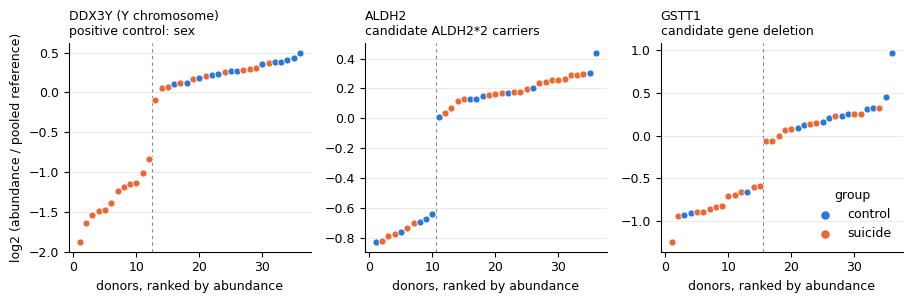

In [7]:
COL = {"control": "#2a78d6", "suicide": "#eb6834"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
panels = [("DDX3Y", "DDX3Y (Y chromosome)\npositive control: sex"), ("ALDH2", "ALDH2\ncandidate ALDH2*2 carriers"), ("GSTT1", "GSTT1\ncandidate gene deletion")]
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.1), sharey=False)
for ax, (g, title) in zip(axes, panels):
    v = L.loc[g].to_numpy(); o = np.argsort(v)
    for rank, j in enumerate(o):
        ax.scatter(rank + 1, v[j], s=26, color=COL[group[j]], edgecolor="white", linewidth=0.6, zorder=3)
    k = int(scan[scan["gene"] == g]["n_low"].iloc[0])
    ax.axvline(k + 0.5, color="#888888", lw=0.8, ls=(0, (3, 3)), zorder=1)
    ax.set_title(title, fontsize=9, loc="left"); ax.set_xlabel("donors, ranked by abundance")
    ax.grid(axis="y", color="#e6e6e6", lw=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("log2 (abundance / pooled reference)")
for lab, c in COL.items():
    axes[2].scatter([], [], s=26, color=c, label=lab)
axes[2].legend(frameon=False, loc="lower right", title="group")
fig.tight_layout()
fig.savefig(RES / "fig_two_cluster_proteins.png", dpi=300)
plt.show()

## Conclusions

- The experimental design (TMT set, channel, sex) is recovered for all 36 samples and saved in `results/sample_map.tsv`. Channel 131 is the pooled reference in every set.
- A simple proteome-wide scan recovers donor sex and flags proteins with private two-cluster patterns.
- ALDH2 and GSTT1 behave as expected for two well-known common germline polymorphisms. Both are **hypotheses at this stage**: the protein table cannot distinguish a genotype from another donor-specific cause. Notebook 06 tests ALDH2\*2 at the peptide level after the raw spectra are re-searched with a variant-aware database.
- If confirmed, GSTT1 illustrates how a germline deletion can be mistaken for a disease marker when the genome is not measured alongside the proteome.